# Higher input resolution

## 1. Research question and hypothesis

Is the existing resize limiting small-object detection? We change only Faster R-CNN resizing from 640/1024 to 800/1280. Both preserve aspect ratio and original-image output coordinates. The optimizer, batch size, anchors, augmentation and selected frames remain fixed.

We test one factor against its own detector baseline. Validation AP and Kaggle Public
can disagree: the earlier Faster R-CNN epoch-one candidate had higher local AP but
lower Public score than epoch five. We do not use Public feedback to tune this ablation.

In [1]:
EXPERIMENT = "input_resolution"

import json
import logging
import math
import sys
from pathlib import Path
from io import BytesIO

import plotly.express as px
import plotly.io
import polars as pl
import torch
from decouple import config
from IPython.display import Markdown, display
from IPython.display import Image as NotebookImage
from PIL import Image, ImageDraw
from torchvision.transforms.functional import pil_to_tensor, to_pil_image

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s [%(levelname)s] %(name)s: %(message)s",
    datefmt="%Y-%m-%dT%H:%M:%S",
    stream=sys.stdout,
    force=True,
)
ROOT = Path.cwd() if Path("pyproject.toml").is_file() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

from experiments.protocol import (
    BATCH_ID,
    baseline_directory,
    baseline_protocol_table,
    choose_example_frames,
    class_table,
    epoch_table,
    load_records,
    load_settings,
    loss_table,
    metric_table,
    runtime_table,
    train_experiment,
)
from hm2.detection_data import select_frames
from hm2.faster_rcnn import IgnoreAwareDetectionDataset, ignore_coverage
from hm2.visualization import draw_frame

SHOULD_TRAIN = False
persist_checkpoint = None
METADATA = Path(config("HM2_METADATA_DIR", default=str(ROOT / "data/metadata"))).expanduser()
manifest = METADATA / "manifest.json"
previous_root = json.loads(manifest.read_text()).get("dataset_root") if manifest.exists() else None
DATA_ROOT = Path(config("HM2_DATA_DIR", default=previous_root or str(ROOT / "data"))).expanduser()
OUTPUT = Path(
    config(
        "HM2_DATA_EXPERIMENT_OUTPUT",
        default=str(ROOT / "runs/data_experiments" / BATCH_ID / EXPERIMENT),
    )
).expanduser()
BASELINE = Path(config("HM2_BASELINE_RESULTS", default=str(baseline_directory(ROOT, EXPERIMENT))))
SETTINGS = load_settings(ROOT, EXPERIMENT)
BASELINE_SETTINGS = load_settings(ROOT, EXPERIMENT, is_enabled=False)
plotly.io.renderers.default = "plotly_mimetype"
pl.Config.set_tbl_rows(12)
pl.Config.set_tbl_cols(12)


def show_image(image: Image.Image) -> None:
    image.thumbnail((1000, 450))
    buffer = BytesIO()
    image.convert("RGB").save(buffer, format="JPEG", quality=40, optimize=True)
    display(NotebookImage(data=buffer.getvalue(), format="jpeg"))


{
    "Experiment": EXPERIMENT,
    "Training enabled": SHOULD_TRAIN,
    "Output": str(OUTPUT),
    "Baseline records": str(BASELINE),
    "Exact configuration": SETTINGS,
}

{'Experiment': 'input_resolution',
 'Training enabled': False,
 'Output': '/home/user/hm2/runs/data_experiments/controlled_data_stride5_5epochs_seed2026/input_resolution',
 'Baseline records': '/home/user/hm2/runs/faster_rcnn/faster_rcnn_stride5_5epochs_seed2026/baseline_stride5',
 'Exact configuration': {'dataset': {'frame_stride': 5,
   'expected_selected_frames': 4868,
   'expected_selected_clips': 56,
   'expected_validation_frames': 2846,
   'should_stage_images': True},
  'model': {'min_size': 800,
   'max_size': 1280,
   'detections_per_img': 500,
   'is_ignore_aware': True,
   'ignore_threshold': 0.5},
  'training': {'seed': 2026,
   'epochs': 5,
   'batch_size': 2,
   'num_workers': 2,
   'learning_rate': 0.0025,
   'warmup_updates': 100,
   'flip_probability': 0.5,
   'checkpoint_seconds': 600},
  'evaluation': {'batch_size': 2, 'num_workers': 2},
  'data_experiment': {'name': 'input_resolution',
   'best_checkpoint': 'Highest full-validation COCO mAP; final epoch is primary'

## 2. Baseline and experimental configuration

We use seed 2026, 4,868 stride-five training frames from 56 clips, full official validation
on 2,846 frames from seven separate clips, batch size 2 and five epochs. SGD uses LR 0.0025,
momentum 0.9 and weight decay 0.0001, with the baseline warmup and two LR reductions.
Initialization uses the original COCO-pretrained detector, never a fine-tuned baseline.
We retain each baseline's anchors, loss, pretrained normalization and inference limits.
The configuration displayed above is loaded from the corresponding TOML file.
The protocol comparison below checks restored original baseline records.

In [2]:
has_metadata = all(
    (METADATA / f"{name}.parquet").is_file() for name in ("frames", "objects", "ignored_regions")
)
selected = validation = frames = objects = ignored = pl.DataFrame()
if has_metadata:
    frames, objects, ignored = (
        pl.read_parquet(METADATA / f"{name}.parquet")
        for name in ("frames", "objects", "ignored_regions")
    )
    selected = select_frames(frames, "train", 5)
    validation = select_frames(frames, "val")
    display(
        pl.DataFrame(
            {
                "Split": ["Training stride 5", "Official validation"],
                "Frames": [selected.height, validation.height],
                "Clips": [selected["clip"].n_unique(), validation["clip"].n_unique()],
            }
        )
    )
else:
    display(
        Markdown(
            "**Data not restored.** Run `00_data.ipynb` or restore the original parquet metadata. No download is started."
        )
    )

has_images = (
    has_metadata and DATA_ROOT.is_dir() and (DATA_ROOT / selected["relative_path"][0]).is_file()
)

Split,Frames,Clips
str,i64,i64
"""Training stride 5""",4868,56
"""Official validation""",2846,7


## 3. Dataset diagnostics and visual examples

About 69% of training boxes were below 32² pixels after the original resize.
We inspect resized dimensions using integer height and width ratios; these are separate
from COCO AP_small, which uses original annotation area. We record memory and throughput
during training. Batch size remains 2; it is never reduced automatically.

Overlay previews show at most 100 GT boxes for readability. Training retains all targets.
The table follows the same median-area GT annotation through both resize settings.

Resize,Median width,Median height,Fraction below 32² resized px
str,f64,f64,f64
"""Baseline""",23.663866,25.277311,0.691707
"""Higher resolution""",29.579832,31.596639,0.542375


**Dark sample, Baseline: 1024 × 576 model pixels.** Display may be downscaled.

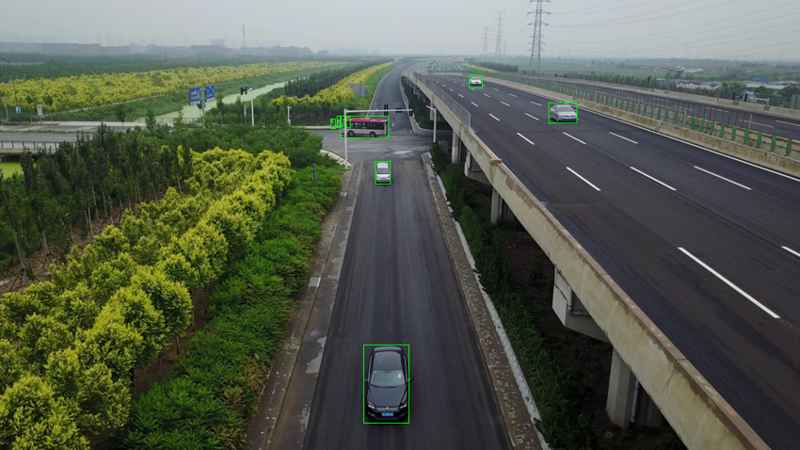

**Dark sample, Higher resolution: 1280 × 720 model pixels.** Display may be downscaled.

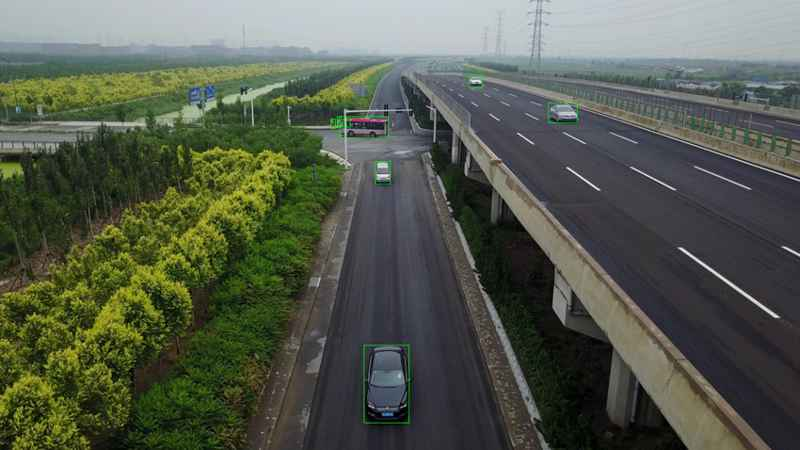

Resize,GT annotation,Original width,Original height,Resized width,Resized height
str,i64,f64,f64,f64,f64
"""Baseline""",431193,43.0,42.0,16.380952,16.0
"""Higher resolution""",431193,43.0,42.0,20.47619,20.0


**Crowded, Baseline: 1024 × 576 model pixels.** Display may be downscaled.

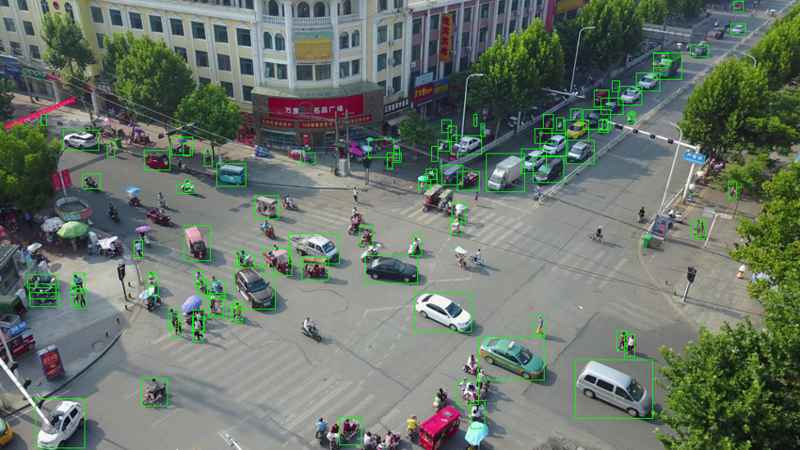

**Crowded, Higher resolution: 1280 × 720 model pixels.** Display may be downscaled.

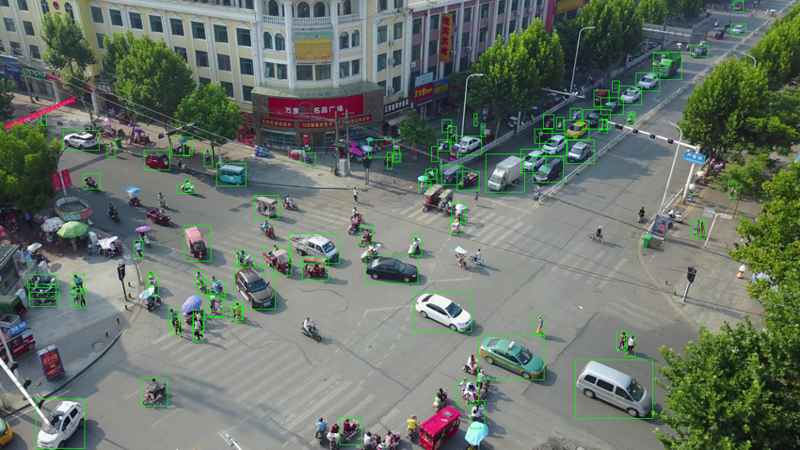

Resize,GT annotation,Original width,Original height,Resized width,Resized height
str,i64,f64,f64,f64,f64
"""Baseline""",471198,37.0,65.0,14.095238,24.761905
"""Higher resolution""",471198,37.0,65.0,17.619048,30.952381


**Small objects, Baseline: 1024 × 576 model pixels.** Display may be downscaled.

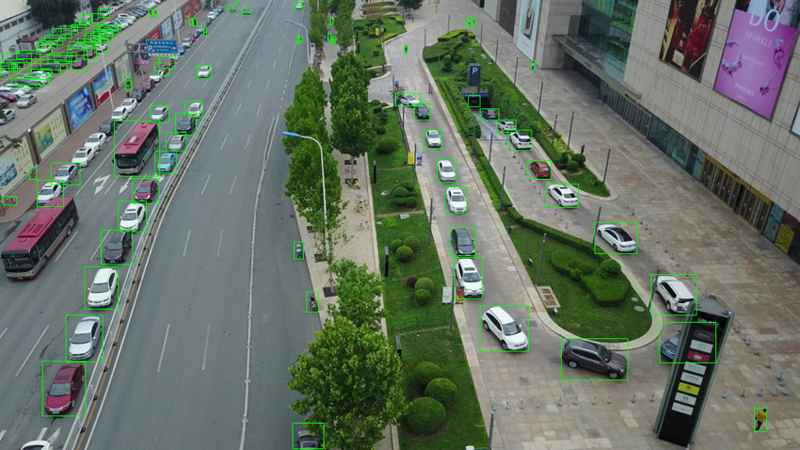

**Small objects, Higher resolution: 1280 × 720 model pixels.** Display may be downscaled.

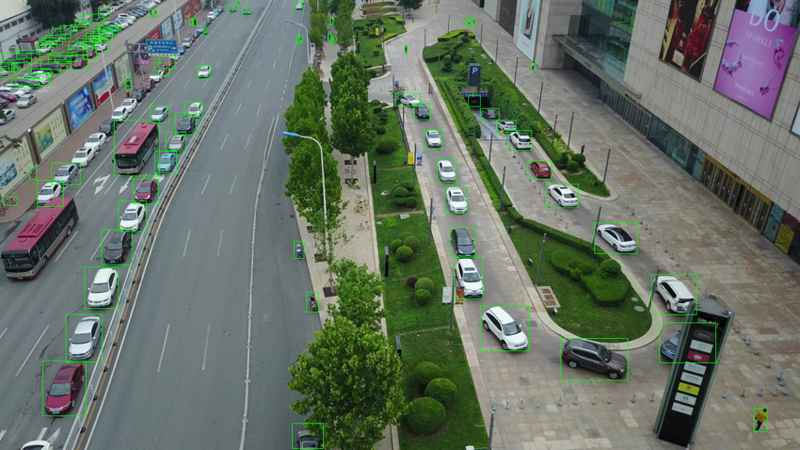

Resize,GT annotation,Original width,Original height,Resized width,Resized height
str,i64,f64,f64,f64,f64
"""Baseline""",166517,55.0,40.0,20.952381,15.238095
"""Higher resolution""",166517,55.0,40.0,26.190476,19.047619


In [3]:
from experiments.input_resolution import (
    resized_box_statistics,
    resized_dimensions,
)

if has_metadata:
    size_rows = []
    for label, minimum, maximum in [("Baseline", 640, 1024), ("Higher resolution", 800, 1280)]:
        sizes = resized_box_statistics(selected, objects, minimum, maximum)
        size_rows.append(
            {
                "Resize": label,
                "Median width": sizes["box_width"].median(),
                "Median height": sizes["box_height"].median(),
                "Fraction below 32² resized px": sizes.select(
                    (pl.col("box_area") < 32**2).mean()
                ).item(),
            }
        )
    display(pl.from_dicts(size_rows))
if has_images:
    for record in choose_example_frames(DATA_ROOT, selected, objects):
        rows = objects.filter(pl.col("image_key") == record["image_key"])
        dimensions = []
        example_box = rows.sort("area").row(rows.height // 2, named=True) if rows.height else None
        for label, minimum, maximum in [("Baseline", 640, 1024), ("Higher resolution", 800, 1280)]:
            height, width = resized_dimensions(
                record["image_height"], record["image_width"], minimum, maximum
            )
            with Image.open(DATA_ROOT / record["relative_path"]) as source:
                image = source.convert("RGB").resize((width, height))
            drawing = ImageDraw.Draw(image)
            if example_box is not None:
                dimensions.append(
                    {
                        "Resize": label,
                        "GT annotation": example_box["annotation_id"],
                        "Original width": example_box["width"],
                        "Original height": example_box["height"],
                        "Resized width": example_box["width"] * width / record["image_width"],
                        "Resized height": example_box["height"] * height / record["image_height"],
                    }
                )
            for box in rows.head(100).iter_rows(named=True):
                sx, sy = width / record["image_width"], height / record["image_height"]
                drawing.rectangle(
                    (
                        box["x"] * sx,
                        box["y"] * sy,
                        (box["x"] + box["width"]) * sx,
                        (box["y"] + box["height"]) * sy,
                    ),
                    outline="lime",
                    width=1,
                )
            image.thumbnail((850, 500))
            display(
                Markdown(
                    f"**{record['Reason']}, {label}: {width} × {height} model pixels.** Display may be downscaled."
                )
            )
            show_image(image)
        if dimensions:
            display(pl.from_dicts(dimensions))

## 4. Experiment execution

We use `experiments/04_data_experiments_kaggle.ipynb` to train this experiment and save
resumable checkpoints to Drive. Set its `EXPERIMENT` to the name shown above.
This research notebook loads saved records; training here remains disabled by default.

In [4]:
if SHOULD_TRAIN:
    if persist_checkpoint is None:
        raise RuntimeError(
            "Configure the verified Drive callback using the execution notebook first."
        )
    if not has_images:
        raise ValueError("Restore local images and metadata before training.")
    display(
        train_experiment(
            EXPERIMENT, DATA_ROOT, METADATA, OUTPUT, SETTINGS, on_checkpoint=persist_checkpoint
        )
    )
else:
    display(
        Markdown(
            "**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized."
        )
    )

**Training disabled.** Use the dedicated execution notebook when GPU execution is authorized.

## 5. Training and validation results

We load measured records on every run. Missing results remain Not run, and unfinished
training remains Partial. Final-epoch metrics are the controlled comparison; best-validation
metrics are shown separately. New ablations retain best.pt, while the historical Faster
R-CNN baseline retained only latest.pt. A best metric in its history does not imply its
old checkpoint is still available. Timings exclude setup and checkpoint transfer.

In [5]:
variant = load_records(OUTPUT)
baseline = load_records(BASELINE)
records = {"Baseline": baseline, "Data variant": variant}
display(metric_table(records))
display(runtime_table(records))
display(baseline_protocol_table(baseline, BASELINE_SETTINGS))
if variant["config"]:
    display(variant["config"])
if variant["status"] == "Not run":
    display(
        Markdown(
            "**Not run.** No trained-variant validation metrics exist yet. Baseline values do not establish an improvement."
        )
    )
if has_images and baseline["config"].get("dataset_selection_sha256"):
    from hm2.faster_rcnn_experiments import compute_source_identity

    keys = selected["image_key"].to_list()
    actual_identity = compute_source_identity(DATA_ROOT, keys)
    display(
        pl.DataFrame(
            {
                "Exact baseline dataset/selection hash matches": [
                    actual_identity == baseline["config"]["dataset_selection_sha256"]
                ]
            }
        )
    )

Run,Status,Selection,Epoch,mAP,AP50,AP75,AP small,AP medium,AP large,Training min,Validation ms/frame
str,str,str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""Baseline""","""Completed""","""Final epoch""",5,0.174703,0.353521,0.152856,0.080675,0.168725,0.334301,75.631758,89.321728
"""Baseline""","""Completed""","""Best validation epoch""",1,0.192021,0.398392,0.161919,0.089808,0.177219,0.354186,15.262009,92.792669
"""Data variant""","""Completed""","""Final epoch""",5,0.208635,0.410092,0.186734,0.103004,0.19068,0.363097,107.832554,109.291461
"""Data variant""","""Completed""","""Best validation epoch""",5,0.208635,0.410092,0.186734,0.103004,0.19068,0.363097,107.832554,109.291461


Run,Status,Training min,Validation min,Images/s,Peak allocated MiB,Minimum free MiB,GPU
str,str,f64,f64,f64,f64,f64,str
"""Baseline""","""Completed""",75.631758,34.744474,5.363708,null,null,"""Tesla T4"""
"""Data variant""","""Completed""",107.832554,41.139744,3.762006,3268.746582,1234.8125,"""Tesla T4"""


Setting,Expected,Recorded,Matches
str,str,str,bool
"""seed""","""2026""","""2026""",true
"""epochs""","""5""","""5""",true
"""batch_size""","""2""","""2""",true
"""learning_rate""","""0.0025""","""0.0025""",true
"""warmup_updates""","""100""","""100""",true
"""flip_probability""","""0.5""","""0.5""",true
"""frame_stride""","""5""","""5""",true
"""min_size""","""640""","""640""",true
"""max_size""","""1024""","""1024""",true


{'data_experiment': {'name': 'input_resolution',
  'best_checkpoint': 'Highest full-validation COCO mAP; final epoch is primary'},
 'experiment_id': 'input_resolution',
 'seed': 2026,
 'epochs': 5,
 'batch_size': 2,
 'learning_rate': 0.0025,
 'warmup_updates': 100,
 'flip_probability': 0.5,
 'frame_stride': 5,
 'selected_frame_count': 4868,
 'dataset_selection_sha256': '3ba20946c7dcea379abcd156f37dbf6ae12931e94fd94f31d24c7c46d1e3ee74',
 'model': {'pretrained': True,
  'min_size': 800,
  'max_size': 1280,
  'anchor_sizes': [32, 64, 128, 256, 512],
  'rpn_pre_nms_top_n_train': 2000,
  'rpn_pre_nms_top_n_test': 1000,
  'rpn_post_nms_top_n_train': 2000,
  'rpn_post_nms_top_n_test': 1000,
  'box_batch_size_per_image': 512,
  'box_positive_fraction': 0.25,
  'detections_per_img': 500,
  'is_ignore_aware': True,
  'ignore_threshold': 0.5,
  'trainable_backbone_layers': 3},
 'optimizer': {'backend': 'SGD', 'momentum': 0.9, 'weight_decay': 0.0001},
 'loss': {'rpn_objectness': 'binary_cross_entr

Exact baseline dataset/selection hash matches
bool
true


## 6. Baseline comparison

We use canonical COCO bbox AP at IoU 0.50:0.95, maxDets [1, 10, 100], and the original
category-specific COCO crowd annotations. Faster R-CNN also records maxDets 500.
The original validation set is unchanged. Metrics are not the competition custom score.
We show each metric on a separate chart to keep axes and legends readable.

In [6]:
epochs = epoch_table(records)
if not epochs.is_empty():
    for metric in ("mAP", "AP50", "AP75", "AP small", "AP medium", "AP large"):
        display(
            px.line(
                epochs.filter(pl.col("Metric") == metric),
                x="Epoch",
                y="AP",
                color="Run",
                markers=True,
                title=f"Validation {metric}",
            ).update_layout(width=1000, height=420, legend=dict(orientation="h", y=-0.25))
        )
classes = class_table(records)
if not classes.is_empty():
    display(classes.pivot(on="Run", index=["Class", "Epoch"], values="AP"))
    display(
        px.bar(
            classes,
            x="Class",
            y="AP",
            color="Run",
            barmode="group",
            title="Per-class AP at the last completed validation",
        ).update_layout(width=1000, height=450, legend=dict(orientation="h", y=-0.25))
    )
for label, record in records.items():
    curve = loss_table(record)
    if not curve.is_empty():
        display(
            px.line(curve, x="Updates", y="Loss", title=f"{label}: training loss").update_layout(
                width=1000, height=420
            )
        )
        display(
            px.line(
                curve, x="Updates", y="Learning rate", title=f"{label}: learning-rate schedule"
            ).update_layout(width=1000, height=380)
        )

Class,Epoch,Baseline,Data variant
str,i64,f64,f64
"""person""",5,0.247199,0.262055
"""bicycle""",5,0.14803,0.201843
"""car""",5,0.356788,0.360469
"""van""",5,0.236865,0.201495
"""truck""",5,0.139097,0.201461
"""tricycle""",5,0.16438,0.187632
"""bus""",5,0.014804,0.145031
"""motor""",5,0.090464,0.109092


## 7. Interpretation and limitations

The restored records contain the completed run. At the final epoch, validation mAP rose
from 0.1747 to 0.2086, AP75 from 0.153 to 0.187 and AP small from 0.081 to 0.103, with
gains in every class except van. Unlike the baseline, the best epoch was the last one,
and training took 107.8 instead of 75.6 minutes. On the Kaggle Public leaderboard the
variant scored 0.19426 against 0.20369 for the baseline, so the validation gain did not
transfer. One hypothesis is the resolution shift: validation frames are 1344 to 3840 px
wide, while test frames are 680 to 1920 px wide, so at 800/1280 about 16% of test frames
are upsampled. We have not tested this hypothesis.

An isolated rare-class change does not establish overall success. A single seed
and only seven validation videos limit generalization claims; GPU runtime changes and
AMP update skips can affect reproducibility. Historical GPU memory was not recorded
for every run and is shown as missing rather than inferred.

We restore original JSON records from Drive only when needed. Use `HM2_BASELINE_RESULTS`
and `HM2_DATA_EXPERIMENT_OUTPUT` to point to restored records. Run the repository from
its root with `uv run jupyter lab notebooks/`. GPU execution uses
`experiments/04_data_experiments_kaggle.ipynb`; setup instructions are in
[the experiment README](../experiments/README.md).

Implementation reference: [TorchVision detection transform source](https://github.com/pytorch/vision/blob/main/torchvision/models/detection/transform.py).